# How a microwave talks to a qubit: the Schrödinger equation with a vector potential
### SymPy derivation · gauge-invariance simulation table · qubit-drive tables (transmon, CSUS bench, toy atom) · same numbers in MATLAB and Lean

**In plain words.** In quantum mechanics a charge doesn't feel the electric field directly. It feels
the **potentials**, through the rule $\mathbf p \to \mathbf p - q\mathbf A$ (minimal coupling).
A microwave or laser pulse is a time-dependent vector potential $A(t)$, and
$E = -\partial A/\partial t$. There are two equivalent ways to write the drive:

* **velocity gauge:** $H = \dfrac{(p - qA)^2}{2m} + V$;
* **length gauge:** $H = \dfrac{p^2}{2m} + V - qE\,x$.

They describe the same physics. A phase factor $e^{iqAx/\hbar}$ converts one into the other, and
measurable results agree whenever $A = 0$. We prove that in SymPy, check it numerically for an
electron in a box, then turn it into the drive strength (Rabi frequency) for three platforms:
- a superconducting **transmon**, where the circuit's flux plays the role of $A$;
- the **CSUS bench** coupled-LC analog, where the mutual inductance $M = kL$ plays that role;
- a toy **electron-in-a-box atom**.

**Same numbers everywhere.** All inputs live in one file, `dgs/qubit_platforms.json`. Python (this
notebook), MATLAB (`learn/matlab/qubit_platforms_table.m`) and Lean (`learn/lean/QubitPlatforms.lean`,
generated from the JSON) each compute or check the table, and the last section compares them. From a
shell, `scripts/check_qubit_platforms_everywhere.sh` does the same and checks every exit code (`$?`).

Figures use the Okabe-Ito palette, curves differ by line style too, and each figure has a printed text
description. Platform values are illustrative orders of magnitude, not a specific device.

In [1]:
import sys, pathlib, math, shutil, subprocess, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, sympy as sp, matplotlib.pyplot as plt
from dgs import vector_potential_qubit as vq
sp.init_printing()
OI = ["#E69F00", "#56B4E9", "#009E73", "#D55E00", "#CC79A7", "#0072B2", "#000000"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)
ROOT = pathlib.Path.cwd().parent
print(json.dumps(vq.load_platforms()["platforms"], indent=1))

{
 "transmon": {
  "label": "superconducting transmon (dilution fridge)",
  "EC_over_h_Hz": 250000000,
  "EJ_over_EC": 50,
  "beta_Cg_over_Csum": 0.001,
  "drive_dBm_at_qubit": -76,
  "Z0_ohm": 50,
  "T_K": 0.015
 },
 "csus_lc_analog": {
  "label": "CSUS bench: two coupled LC tanks (classical analog)",
  "L_H": 3.6237148913e-05,
  "C_F": 3.3e-09,
  "C_probe_F": 1.2e-11,
  "k": 0.0806173509,
  "gap_m": 0.02,
  "T_K": 295
 },
 "box_atom": {
  "label": "electron in a 1 nm box driven by a laser field (toy artificial atom)",
  "a_m": 1e-09,
  "E0_Vpm": 1000000,
  "T_K": 295
 }
}


## 1. Velocity gauge → length gauge (SymPy)

Put $\psi = e^{iqA(t)x/\hbar}\,\varphi$ into $i\hbar\,\partial_t\psi = \big[(p-qA)^2/2m + V\big]\psi$,
with $A$ uniform over the atom (dipole approximation). The momentum operator acting on the phase
cancels the $-qA$, and $\partial_t$ acting on the phase produces $-q\dot A\,x = qE\,x$. SymPy
checks that the difference of the two equations is identically zero:

residual  [i hbar d_t psi - H_v psi] - e^{iqAx/hbar} [i hbar d_t phi - H_L phi]  = 0
length-gauge Hamiltonian acting on phi:


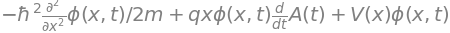

In [2]:
g = vq.derive_gauge_transform()
print("residual  [i hbar d_t psi - H_v psi] - e^{iqAx/hbar} [i hbar d_t phi - H_L phi]  =", g["residual"])
print("length-gauge Hamiltonian acting on phi:"); display(g["H_length_phi"])

## 2. Matrix elements of an electron in a box (SymPy)

For a box $0 < x < a$, SymPy integrates the general matrix elements. The 1→2 dipole element is
$x_{12} = -16a/(9\pi^2)$, and the commutator $[H, x] = -i\hbar p/m$ forces
$p_{mn} = i m\,\omega_{mn}\,x_{mn}$, so both gauges give the same two-level Rabi frequency on resonance:
$qE_0|x_{12}|/\hbar = (q/m)A_0|p_{12}|/\hbar$ with $A_0 = E_0/\omega$.

<m|x|n> =


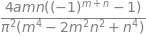

<m|d/dx|n> =


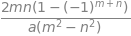

x_12 = -16*a/(9*pi**2)    d/dx_12 = -8/(3*a)


In [3]:
me_ = vq.box_matrix_elements_symbolic()
print("<m|x|n> ="); display(me_["x_mn"])
print("<m|d/dx|n> ="); display(me_["ddx_mn"])
m, n = sp.symbols("m n", positive=True, integer=True)
print("x_12 =", sp.simplify(me_["x_mn"].subs({m: 1, n: 2})), "   d/dx_12 =", sp.simplify(me_["ddx_mn"].subs({m: 1, n: 2})))

## 3. Simulation table: both gauges, growing basis

Units are $\hbar = m = a = 1$. A pulse $A(t) = A_0\sin^2(\pi t/T)\sin(\omega_{12} t)$, which is zero at
both ends, lasts 40 periods. Its area is set for a π pulse (|1⟩ → |2⟩). It is run in the length gauge
and the velocity gauge with $N$ box levels kept. Because $A(T) = 0$, the final populations must agree,
up to basis truncation.

In [4]:
rows = vq.gauge_table((2, 3, 4, 8, 16))
hdr = [sp.Symbol("N"), sp.Symbol("P_2^{(length)}"), sp.Symbol("P_2^{(velocity)}"), sp.Symbol("|\Delta P_2|"), sp.Symbol("leak^{(length)}_{n \geq 3}")]
tab = sp.Matrix([hdr] +
                [[r["N"], sp.Float(r["P2_length"], 8), sp.Float(r["P2_velocity"], 8), sp.Float(r["diff"], 3),
                  sp.Float(max(r["leak_length"], 0), 3)] for r in rows])
display(tab)
print("Reading: P2 is about 0.9992 rather than 1 because the pulse area was set with the rotating-wave estimate; "
      f"the two gauges agree to {rows[-1]['diff']:.1e} with 16 levels (vs {rows[0]['diff']:.1e} with 2). The difference "
      "is not strictly monotone in N (N = 4 is a little worse than N = 3); the velocity gauge needs more levels "
      "because its p matrix elements fall off more slowly than x's.")

<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\g'
<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\g'
C:\Users\mrjel\AppData\Local\Temp\ipykernel_10024\1024639526.py:2: SyntaxWarning: invalid escape sequence '\D'
  hdr = [sp.Symbol("N"), sp.Symbol("P_2^{(length)}"), sp.Symbol("P_2^{(velocity)}"), sp.Symbol("|\Delta P_2|"), sp.Symbol("leak^{(length)}_{n \geq 3}")]
C:\Users\mrjel\AppData\Local\Temp\ipykernel_10024\1024639526.py:2: SyntaxWarning: invalid escape sequence '\g'
  hdr = [sp.Symbol("N"), sp.Symbol("P_2^{(length)}"), sp.Symbol("P_2^{(velocity)}"), sp.Symbol("|\Delta P_2|"), sp.Symbol("leak^{(length)}_{n \geq 3}")]


⎡N   P_2__{(length)}  P_2__{(velocity)}  |\Delta P_2|  leak_{n \geq 3}__{(leng ↪
⎢                                                                              ↪
⎢2     0.99973473         0.9999705        0.000236                0.0         ↪
⎢                                                                              ↪
⎢3     0.99920684        0.99924233        3.55e-5              5.46e-10       ↪
⎢                                                                              ↪
⎢4     0.99920755        0.99926019        5.26e-5              5.48e-10       ↪
⎢                                                                              ↪
⎢8      0.9992066        0.99921147        4.87e-6              5.48e-10       ↪
⎢                                                                              ↪
⎣16     0.9992066        0.99920714        5.45e-7              5.46e-10       ↪

↪ th)}⎤
↪     ⎥
↪     ⎥
↪     ⎥
↪     ⎥
↪     ⎥
↪     ⎥
↪     ⎥
↪     ⎥
↪     ⎥
↪     ⎦

Reading: P2 is about 0.9992 rather than 1 because the pulse area was set with the rotating-wave estimate; the two gauges agree to 5.5e-07 with 16 levels (vs 2.4e-04 with 2). The difference is not strictly monotone in N (N = 4 is a little worse than N = 3); the velocity gauge needs more levels because its p matrix elements fall off more slowly than x's.


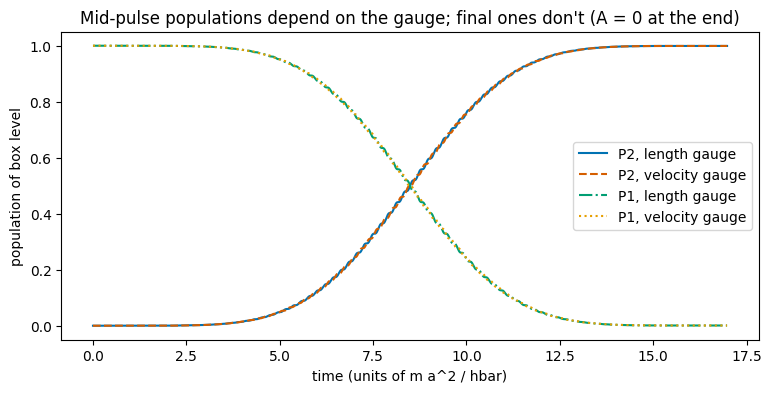

Text description: populations of box levels 1 and 2 during the pulse, N = 16. Level 2 rises from 0 to nearly 1 and level 1 falls, crossing near mid-pulse; length gauge solid blue (level 2) and dash-dot green (level 1), velocity gauge dashed vermillion (2) and dotted orange (1). At this scale the pairs look the same, but they are not equal mid-pulse: the largest gap in P2 is 0.0133, at 50 % of the pulse, because while A is non-zero 'population of a box level' is not a gauge-invariant quantity. At the end, where A = 0, the gap is 5.5e-07 (P2 = 0.999207 vs 0.999207).


In [5]:
tL, pL = vq.simulate_box(16, "length", history=True)
tV, pV = vq.simulate_box(16, "velocity", history=True)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tL, pL[:, 1], "-", color=OI[5], label="P2, length gauge")
ax.plot(tV, pV[:, 1], "--", color=OI[3], label="P2, velocity gauge")
ax.plot(tL, pL[:, 0], "-.", color=OI[2], label="P1, length gauge")
ax.plot(tV, pV[:, 0], ":", color=OI[0], label="P1, velocity gauge")
ax.set_xlabel("time (units of m a^2 / hbar)"); ax.set_ylabel("population of box level"); ax.legend()
ax.set_title("Mid-pulse populations depend on the gauge; final ones don't (A = 0 at the end)")
plt.show()
dP = np.abs(pL[:, 1] - pV[:, 1])
print(f"Text description: populations of box levels 1 and 2 during the pulse, N = 16. Level 2 rises from 0 to nearly 1 and "
      f"level 1 falls, crossing near mid-pulse; length gauge solid blue (level 2) and dash-dot green (level 1), velocity gauge "
      f"dashed vermillion (2) and dotted orange (1). At this scale the pairs look the same, but they are not equal mid-pulse: "
      f"the largest gap in P2 is {dP.max():.4f}, at {tL[dP.argmax()]/tL[-1]*100:.0f} % of the pulse, because while A is "
      f"non-zero 'population of a box level' is not a gauge-invariant quantity. At the end, where A = 0, the gap is "
      f"{dP[-1]:.1e} (P2 = {pL[-1,1]:.6f} vs {pV[-1,1]:.6f}).")

## 4. Qubit-drive tables (SymPy), from `dgs/qubit_platforms.json`

Each platform has its own "vector potential":
- **Transmon:** the drive voltage $V(t) = -\dot\Phi$, so the node flux $\Phi$ plays the role of $A$.
  The drive couples to the island charge: $\Omega = 2e\beta V_0\langle 0|n|1\rangle/\hbar$.
  In the transmon limit, $\langle 0|n|1\rangle = (E_J/8E_C)^{1/4}/\sqrt2$ and
  $f_{01} = (\sqrt{8E_JE_C} - E_C)/h$.
- **CSUS LC analog:** the flux linkage per ampere, $M = kL$, is the coupling, and $\Omega \approx k\omega_0$.
- **Box atom:** a laser field $E_0$, with both gauges shown side by side.

In [6]:
T = vq.sympy_table()
for plat, rows_ in T.items():
    print(f"=== {plat}")
    display(sp.Matrix([[sp.Symbol(q.replace(' ', '~')), ex, sp.Float(val, 6)] for q, ex, val in rows_]))

=== transmon


⎡                                 2⋅√2⋅E_C⋅√r - E_C             ⎤
⎢           f01~(Hz)              ─────────────────    4.75e+9  ⎥
⎢                                         h                     ⎥
⎢                                                               ⎥
⎢                                     3/4 4 ___                 ⎥
⎢                                    2   ⋅╲╱ r                  ⎥
⎢            <0|n|1>                 ──────────        1.11803  ⎥
⎢                                        4                      ⎥
⎢                                                               ⎥
⎢                                  3/4        4 ___             ⎥
⎢                                 2   ⋅V₀⋅β⋅e⋅╲╱ r              ⎥
⎢         Omega~(rad/s)           ─────────────────  1.70263e+8 ⎥
⎢                                        2⋅h̅                    ⎥
⎢                                                               ⎥
⎢                                    4 ___                      ⎥
⎢        

=== csus_lc_analog


⎡                                  1                    ⎤
⎢        f0~(Hz)           ─────────────────   459407.0 ⎥
⎢                                   ________            ⎥
⎢                          2⋅√L⋅π⋅╲╱ C + Cₚ             ⎥
⎢                                                       ⎥
⎢                                  k                    ⎥
⎢Omega~=~k~omega0~(rad/s)    ─────────────     232705.0 ⎥
⎢                                 ________              ⎥
⎢                            √L⋅╲╱ C + Cₚ               ⎥
⎢                                                       ⎥
⎢                                  ________             ⎥
⎢                           √L⋅π⋅╲╱ C + Cₚ              ⎥
⎢ swap~time~pi/Omega~(s)    ───────────────   1.35003e-5⎥
⎢                                  k                    ⎥
⎢                                                       ⎥
⎣     M~=~k~L~(Wb/A)              L⋅k         2.92134e-6⎦

=== box_atom


⎡                                 3⋅h̅⋅π                ⎤
⎢          f12~(Hz)              ───────    2.72771e+14⎥
⎢                                   2                  ⎥
⎢                                4⋅a ⋅mₑ               ⎥
⎢                                                      ⎥
⎢                                  16⋅a                ⎥
⎢          |x12|~(m)               ────     1.80127e-10⎥
⎢                                     2                ⎥
⎢                                  9⋅π                 ⎥
⎢                                                      ⎥
⎢                               16⋅E₀⋅a⋅e              ⎥
⎢ Omega,~length~gauge~(rad/s)   ─────────   2.7366e+11 ⎥
⎢                                     2                ⎥
⎢                                9⋅h̅⋅π                 ⎥
⎢                                                      ⎥
⎢                               16⋅E₀⋅a⋅e              ⎥
⎢Omega,~velocity~gauge~(rad/s)  ─────────   2.7366e+11 ⎥
⎢                            

In [7]:
d = vq.derived()
labels = {"transmon": "transmon (15 mK)", "csus_lc_analog": "CSUS LC bench (295 K)", "box_atom": "box atom (295 K)"}
print(f"{'platform':24s} {'f_transition':>14s} {'f_Rabi':>12s} {'t_pi':>11s} {'vector-potential amp':>22s} {'thermal n':>11s}")
for k_, r in d.items():
    unit = "V s/m" if k_ == "box_atom" else ("Wb/A" if k_ == "csus_lc_analog" else "Wb")
    print(f"{labels[k_]:24s} {r['f_transition_Hz']:12.4g} Hz {r['f_Rabi_Hz']:9.4g} Hz {r['t_pi_s']:9.3g} s "
          f"{r['vector_potential_amp']:14.4g} {unit:6s} {r['n_thermal']:11.3g}")
print("\nThe thermal column is why the CSUS analog is classical: about 1.3e7 thermal quanta per mode at 460 kHz and room "
      "temperature, against 2.5e-7 for the transmon at 15 mK. Same equation of motion, opposite regime.")

platform                   f_transition       f_Rabi        t_pi   vector-potential amp   thermal n
transmon (15 mK)             4.75e+09 Hz  2.71e+07 Hz  1.85e-08 s      1.679e-15 Wb        2.51e-07
CSUS LC bench (295 K)       4.594e+05 Hz 3.704e+04 Hz  1.35e-05 s      2.921e-06 Wb/A      1.34e+07
box atom (295 K)            2.728e+14 Hz 4.355e+10 Hz  1.15e-11 s      5.835e-10 V s/m     5.34e-20

The thermal column is why the CSUS analog is classical: about 1.3e7 thermal quanta per mode at 460 kHz and room temperature, against 2.5e-7 for the transmon at 15 mK. Same equation of motion, opposite regime.


## 5. Same numbers in MATLAB and Lean

* **MATLAB** reads the same JSON, recomputes every derived value with its own code, and prints the
  same `platform.key value` lines. Python compares them line by line.
* **Lean** compiles the file generated from the JSON against Mathlib. It proves:
  - the gauge-coupling identity;
  - the box commutator identity, for the SymPy closed forms;
  - $x_{12}$;
  - Rabi contrast ≤ 1;
  - the CSUS series-aiding recipe;
  - $f_{01} = 19E_C/h = 4.75$ GHz exactly for the JSON's $E_J/E_C = 50$.

  If the JSON changes and the Lean file isn't regenerated, `tests/test_vector_potential_qubit.py` fails.

Each step prints its exit code; nothing is reported as verified unless the code is 0.

In [8]:
status = {}
matlab = shutil.which("matlab") or next((str(p) for p in [pathlib.Path(r"C:\Program Files\MATLAB\R2025b\bin\matlab.exe")] if p.exists()), None)
if matlab:
    r = subprocess.run([matlab, "-batch", "run('learn/matlab/qubit_platforms_table.m')"], cwd=ROOT, capture_output=True, text=True, timeout=600)
    status["matlab"] = r.returncode
    bad = vq.compare_tables(vq.parse_table("\n".join(vq.table_lines())), vq.parse_table(r.stdout), rtol=1e-11)
    status["python_vs_matlab"] = 0 if (r.returncode == 0 and not bad) else 1
    print(f"MATLAB exit code {r.returncode}; {len(vq.parse_table(r.stdout))} values; mismatches vs Python (rtol 1e-11): {bad or 'none'}")
else:
    print("MATLAB not found: NOT checked")
proj = pathlib.Path.home() / "lean" / "NavierStokesAndEuler"
lake = shutil.which("lake") or str(pathlib.Path.home() / ".elan" / "bin" / "lake.exe")
lean_file = ROOT / "learn" / "lean" / "QubitPlatforms.lean"
in_sync = lean_file.read_text(encoding="utf-8") == vq.lean_source()
print("Lean file in sync with JSON:", in_sync)
if proj.exists() and pathlib.Path(lake).exists():
    r = subprocess.run([lake, "env", "lean", str(lean_file)], cwd=proj, capture_output=True, text=True, timeout=1800)
    ok = r.returncode == 0 and "sorry" not in (r.stdout + r.stderr) and in_sync
    status["lean"] = 0 if ok else 1
    print(f"Lean exit code {r.returncode}; theorems:", ", ".join(l.split()[1] for l in lean_file.read_text(encoding='utf-8').splitlines() if l.startswith("theorem ")))
    if r.returncode:
        print(r.stdout[-2000:], r.stderr[-2000:])
else:
    print("Lean/Mathlib project not found: NOT checked")
print("\nexit codes:", status, "->", "ALL OK" if status and all(v == 0 for v in status.values()) else "SOMETHING FAILED OR WAS SKIPPED")

MATLAB exit code 0; 23 values; mismatches vs Python (rtol 1e-11): none
Lean file in sync with JSON: True


Lean exit code 0; theorems: gauge_coupling_equal, box_commutator, box_x12, rabi_contrast_le_one, csus_series_recipe, transmon_f01

exit codes: {'matlab': 0, 'python_vs_matlab': 0, 'lean': 0} -> ALL OK


## How this connects

* **Qubit chain:** `qubit_microwave_lab.ipynb` covers the chain that delivers the transmon's $V_0$
  (−76 dBm at the qubit) and the CSUS bench protocol (`docs/csus_qubit_analog_lab.md`). Its 13.5 µs
  swap time is the $t_\pi$ in the CSUS row above.
* **Griffiths:** potentials and gauges (ED ch. 10); particle in a box and time-dependent perturbation
  theory (QM ch. 2 and 11) in `griffiths/`.
* **Tests:** `PYTHONPATH=. python -m pytest tests/test_vector_potential_qubit.py -q`.
* **Every tool at once, with exit codes:** `bash scripts/check_qubit_platforms_everywhere.sh`.

**References** (IEEE style, written from memory; check details before citing):

[1] D. J. Griffiths and D. F. Schroeter, *Introduction to Quantum Mechanics*, 3rd ed. Cambridge, U.K.: Cambridge Univ. Press, 2018.
[2] J. Koch *et al.*, "Charge-insensitive qubit design derived from the Cooper pair box," *Phys. Rev. A*, vol. 76, no. 4, 042319, 2007.
[3] P. Krantz *et al.*, "A quantum engineer's guide to superconducting qubits," *Appl. Phys. Rev.*, vol. 6, no. 2, 021318, 2019.
[4] W. E. Lamb, R. R. Schlicher, and M. O. Scully, "Matter-field interaction in atomic physics and quantum optics," *Phys. Rev. A*, vol. 36, no. 6, pp. 2763-2772, 1987.